# Visualizing fire scars through false color
### EDS 220 Homework 4 - Task 2

**Author**: Karolina Sienko

**GitHub Repository**: https://github.com/karolinasienko/eds220-hwk4

#### About the Notebook

**Purpose**:

This notebook is for Homework 4 for EDS 220: Working with Environmental Datasets. The analysis visualizes the Eaton and Palisades fires from January 2021 through both true and false imagery. To do so, it uses one Landsat dataset that was clipped to an area surrounding the fire perimeters and two other datasets containing the fire perimeters.


**Highlights**:

* Data exploration with `pandas`
* Exploring and wrangling raster data stored in a netCDF file using `xarray` and `rioxarray`
* Handling outliers and missing values that restrict plotting
* Creating and customizing true and false color image maps
* Combining raster and vector data to map fire scars


**About the data**:

This analysis uses three datasets. The first two are fire perimeter data for the Eaton and Palisades fires from the [County of Los Angeles Enterprise GIS](https://egis-lacounty.hub.arcgis.com/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about), which was pulled from CAL FIRE's Historical Fire Perimeter Dataset. It was downloaded as two separate shapefiles, one for each fire. The third dataset was for Landsat, was retrieved from the [Microsoft Planetary Computer data catalog](https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2) and clipped to an area surrounding the fire perimeters. This data should be used for visualization and educational purposes only, and was downloaded from the course's shared Google Drive.


**References**:

Los Angeles County. (2025). Palisades and Eaton dissolved fire perimeters (2025) [GIS dataset]. *Los Angeles County Enterprise GIS*. https://egis-lacounty.hub.arcgis.com/datasets/lacounty::palisades-and-eaton-dissolved-fire-perimeters-2025

Microsoft. (n.d.). Landsat Collection 2 Level-2. *Microsoft Planetary Computer*. https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2

In [2]:
# Import packages           
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import matplotlib.pyplot as plt

import xarray as xr 

#### 1. Reading

Read the following resources about false color images and Landsat imagery:

* [NASA Earth Observatory - Why is that Forest Red and that Cloud Blue? How to Interpret a False-Color Satellite Image](https://science.nasa.gov/earth/earth-observatory/how-to-interpret-a-false-color-satellite-image/)

* [What are the band designations for the Landsat satellites?](https://www.usgs.gov/faqs/what-are-band-designations-landsat-satellites)

* [Common Landsat Band Combinations](https://www.usgs.gov/media/images/common-landsat-band-combinations)

#### 2. Fire perimeter data exploration

Explore the fire perimeter data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include, at least, the CRS of the data and whether this is projected or geographic.

In [3]:
# Reading in the fire perimeter data
eaton = gpd.read_file(os.path.join('data',
                                    'Eaton_Perimeter', 
                                    'Eaton_Perimeter_20250121.shp'))
palisades = gpd.read_file(os.path.join('data',
                                       'Palisades_Perimeter', 
                                       'Palisades_Perimieter_20250121.shp'))

In [4]:
# Glimpsing the data frame
eaton.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LAC,EATON,Heat Perimeter,00009087,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},2025-01-08T00:00:00Z,...,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026,"MULTIPOLYGON (((-118.10093 34.16680, -118.1008..."


In [5]:
# Gett the CRS
eaton.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [6]:
# Relevant info on data frame
eaton.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 24 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    1 non-null      int64   
 1   YEAR_       1 non-null      int64   
 2   STATE       1 non-null      object  
 3   AGENCY      1 non-null      object  
 4   UNIT_ID     1 non-null      object  
 5   FIRE_NAME   1 non-null      object  
 6   type        1 non-null      object  
 7   INC_NUM     1 non-null      object  
 8   IRWINID     1 non-null      object  
 9   ALARM_DATE  1 non-null      object  
 10  CONT_DATE   1 non-null      object  
 11  CAUSE       1 non-null      int64   
 12  C_METHOD    1 non-null      int64   
 13  OBJECTIVE   1 non-null      int64   
 14  GIS_ACRES   1 non-null      float64 
 15  COMMENTS    0 non-null      object  
 16  COMPLEX_NA  0 non-null      object  
 17  COMPLEX_ID  0 non-null      object  
 18  FIRE_NUM    0 non-null      object  
 19  Glob

In [7]:
# Glimpse the data frame
palisades.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LDF,PALISADES,Heat Perimeter,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07T00:00:00Z,...,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614,"MULTIPOLYGON (((-118.51974 34.02996, -118.5198..."


In [8]:
# Gett the CRS
palisades.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [9]:
# Relevant info of data frame
palisades.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 24 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    1 non-null      int64   
 1   YEAR_       1 non-null      int64   
 2   STATE       1 non-null      object  
 3   AGENCY      1 non-null      object  
 4   UNIT_ID     1 non-null      object  
 5   FIRE_NAME   1 non-null      object  
 6   type        1 non-null      object  
 7   INC_NUM     1 non-null      object  
 8   IRWINID     1 non-null      object  
 9   ALARM_DATE  1 non-null      object  
 10  CONT_DATE   1 non-null      object  
 11  CAUSE       1 non-null      int64   
 12  C_METHOD    1 non-null      int64   
 13  OBJECTIVE   1 non-null      int64   
 14  GIS_ACRES   1 non-null      float64 
 15  COMMENTS    0 non-null      object  
 16  COMPLEX_NA  0 non-null      object  
 17  COMPLEX_ID  0 non-null      object  
 18  FIRE_NUM    0 non-null      object  
 19  Glob

**Data exploration summary**

Both the `eaton` and `palisades` fire perimeter datasets come from shapefiles that eacg have 1 row and 24 columns that represent a fire boundary. They have the same CRS, EPSG:4269. Since this is a geographic CRS, coordinates are stored as latitude and longitude on an ellipsoid instead of being projected onto a flat plane. Therefore, it will need to be reprojected before mapping to match the Landsat data's CRS.

#### 3. NetCDF data import and exploration

a. Import the Landsat data using `xr.open_dataset()`.

b. Explore the data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include a description of the data’s variables, dimensions, and coordinates.

In [10]:
# Load in Landsat data
landsat = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')

In [11]:
# Glimpse the dataset
landsat.head()

<xarray.Dataset> Size: 596B
Dimensions:      (y: 5, x: 5)
Coordinates:
  * y            (y) float64 40B 3.799e+06 3.799e+06 ... 3.799e+06 3.799e+06
  * x            (x) float64 40B 3.344e+05 3.344e+05 ... 3.345e+05 3.345e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 100B ...
    green        (y, x) float32 100B ...
    blue         (y, x) float32 100B ...
    nir08        (y, x) float32 100B ...
    swir22       (y, x) float32 100B ...
    spatial_ref  int64 8B ...

In [12]:
# Relevant info of dataset
landsat.info()

xarray.Dataset {
dimensions:
	y = 1418 ;
	x = 2742 ;

variables:
	float64 y(y) ;
		y:units = metre ;
		y:resolution = -30.0 ;
		y:crs = EPSG:32611 ;
		y:axis = Y ;
		y:long_name = y coordinate of projection ;
		y:standard_name = projection_y_coordinate ;
	float64 x(x) ;
		x:units = metre ;
		x:resolution = 30.0 ;
		x:crs = EPSG:32611 ;
		x:axis = X ;
		x:long_name = x coordinate of projection ;
		x:standard_name = projection_x_coordinate ;
	datetime64[ns] time() ;
	float32 red(y, x) ;
		red:grid_mapping = spatial_ref ;
	float32 green(y, x) ;
		green:grid_mapping = spatial_ref ;
	float32 blue(y, x) ;
		blue:grid_mapping = spatial_ref ;
	float32 nir08(y, x) ;
		nir08:grid_mapping = spatial_ref ;
	float32 swir22(y, x) ;
		swir22:grid_mapping = spatial_ref ;
	int64 spatial_ref() ;
		spatial_ref:crs_wkt = PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["

**Data exploration summary**

The Landsat dataset has two dimensions: y (1418) and x (2742). The units for the data are in meters, so the resolution is 30 m. There is also one time coordinate, since this is one image from February 23, 2025. The data variables are red, green, blue, near-infrared (nir08), and shortwave infrared (swir22). The spatial_ref variable stores the CRS information, which is UTM zone 11N EPSG:32611, a projected CRS.

#### 4. Restoring geospatial information

a. Use `rio.crs` to print the CRS of this dataset. Is this a geospatial object?

In [13]:
# Try to print the CRS of the dataset
print(landsat.rio.crs)

None


Printing `landsat.rio.crs` returns `None`, which means that Python does not see this as a geospatial object because the CRS information only exists in the file within the `spatial_ref` variable.

b. You may have noticed in section 3 that the geospatial information for this dataset is stored in the variable `spatial_ref`. Print the CRS by accessing the `spatial_ref.crs_wkt` attribute of the dataset.

In [14]:
# Print the CRS of the dataset
crs = landsat.spatial_ref.crs_wkt
print(crs)

PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


c. Recover the geospatial information by using `rio.write_crs()` and the spatial reference information from part b.

In [15]:
# Save the wkt CRS into Landsat data 
landsat = landsat.rio.write_crs(crs)

d. Print the CRS of the updated dataset.

In [16]:
# Print the CRS of the dataset
print(landsat.rio.crs)

EPSG:32611


#### 5. True color image

a. Without creating any new variables:
* select the red, green, and blue variables (in that order) of the `xarray.Dataset` holding the Landsat data,
* convert it to an `xarray.DataArray` using the `to_dataarray()` method, and then
* use `.plot.imshow()` to create an RGB image with the data. There will be a warning; that’s ok.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


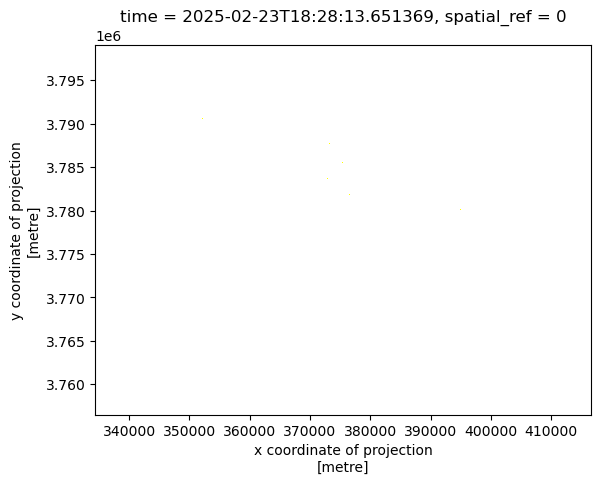

In [26]:
# Plot the selected bands for true color image
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow()

plt.show()

b. Adjust the scale used for plotting the bands to get a true color image. HINT: Check the robust parameter.

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


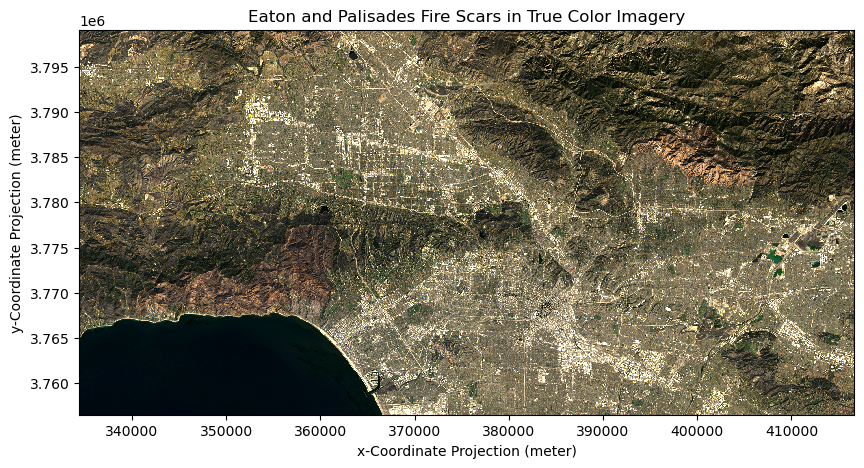

In [18]:
# Plot the true color image with robust=True
fig, ax = plt.subplots(figsize=(10,5))

landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust=True)

# Relabel the axes and title
plt.xlabel('x-Coordinate Projection (meter)')
plt.ylabel('y-Coordinate Projection (meter)')
plt.title('Eaton and Palisades Fire Scars in True Color Imagery')

plt.show()

c. To resolve the other warning, identify which bands have `nan` values. HINT: There are many ways of doing so. One option is to use `numpy.isnan()`.

In [19]:
# Determine which bands have nan values and how many
bands = ['red', 'green', 'blue', 'nir08', 'swir22']

for band in bands:
    num_na = int(np.isnan(landsat[band]).sum())
    print(f"The {band} band has {num_na} NA values.")

The red band has 0 NA values.
The green band has 1 NA values.
The blue band has 109 NA values.
The nir08 band has 0 NA values.
The swir22 band has 0 NA values.


d. Use the `.fillna()` method for `xarray.Datasets` to replace any nan values in the Landsat data with zero.

In [20]:
# Replace landsat nan values with zeroes
landsat = landsat.fillna(value=0)

e. Create a new true color image that gets plotted without warnings.

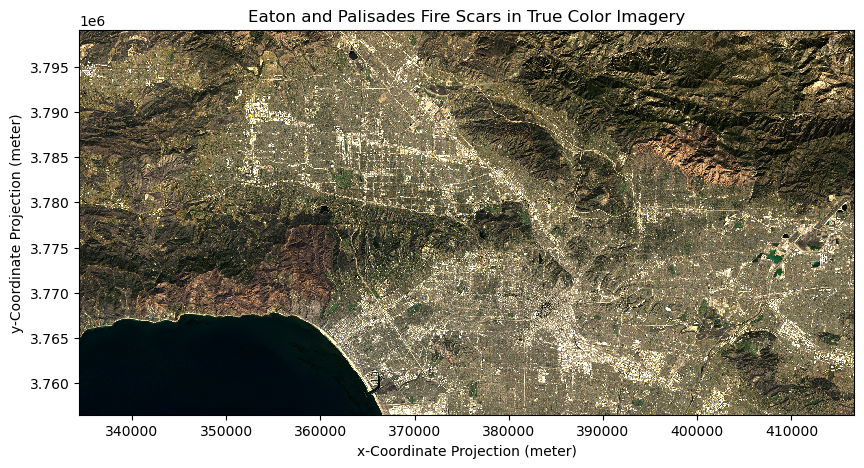

In [21]:
# Plot true color image again, without warnings
fig, ax = plt.subplots(figsize=(10,5))

landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust=True)

# Relabel the axes and title
plt.xlabel('x-Coordinate Projection (meter)')
plt.ylabel('y-Coordinate Projection (meter)')
plt.title('Eaton and Palisades Fire Scars in True Color Imagery')

plt.show()

f. In a markdown cell write a brief explanation comparing the outputs for parts (a) and (e).

The output of (a) was just a blank plot because the Landsat values were much larger than the 0-1 range that `.plot.imshow()` expects. After we added the `robust` parameter and set it to `True`, the colormap range could be computed with 2ns and 98th percentiles instead of the extreme values. We used `fillna()` to replace nan values in the data with zeroes, which removed the warning and allow the image to plot.

#### 6. False color image

Without creating any new variables, create a false color image by plotting the shortwave infrared (swir22), near-infrared, and red variables (in that order).

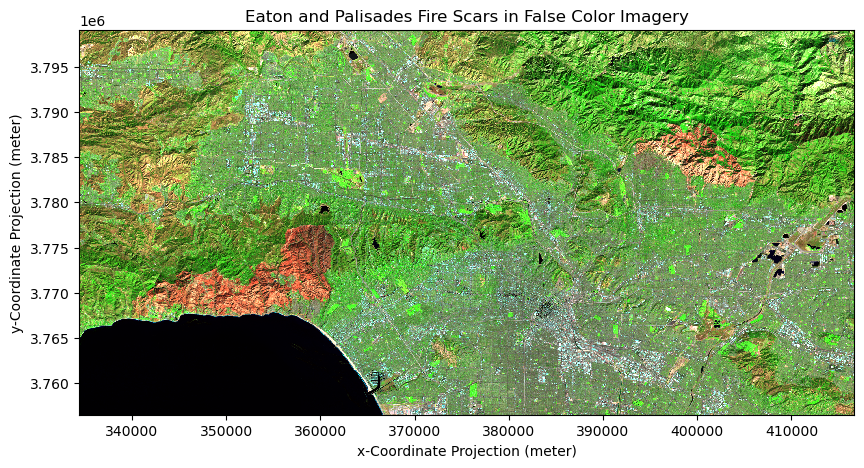

In [22]:
# Plot false color image
fig, ax = plt.subplots(figsize=(10,5))

# Select certain bands to concert to a DataArray to plot
landsat[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(robust=True)

# Relabel the axes and title
plt.xlabel('x-Coordinate Projection (meter)')
plt.ylabel('y-Coordinate Projection (meter)')
plt.title('Eaton and Palisades Fire Scars in False Color Imagery')

plt.show()

#### 7. Map

a. Create a map showing the shortwave infrared/near-infrared/red false color image together with both fire *perimeters*. Customize it appropriately including, at least, an informative title and legend. You may also want to include text on the map to identify which fire is which.

In [23]:
# Data preparation

# Change fire perimeter CRS to match Landsat CRS
eaton = eaton.to_crs(landsat.rio.crs)
palisades = palisades.to_crs(landsat.rio.crs)

# Make sure CRS' match
assert eaton.crs == landsat.rio.crs
assert palisades.crs == landsat.rio.crs

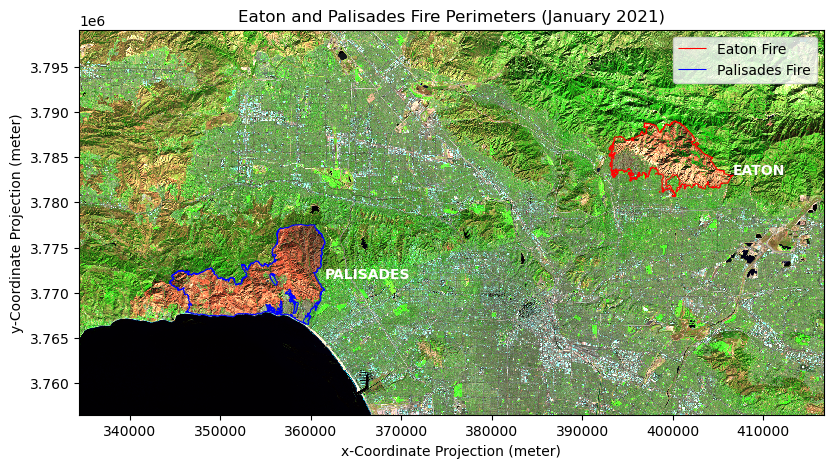

In [25]:
# Find max coordinates of fire polygons to add fire names as text annotations
eaton_max_coord = eaton.geometry.get_coordinates().max()
palisades_max_coord = palisades.geometry.get_coordinates().max()

# Add max coordinates to iterable list
max_x = [eaton_max_coord.iloc[0], palisades_max_coord.iloc[0]]
max_y = [eaton_max_coord.iloc[1], palisades_max_coord.iloc[1]]


# Plot false color image

fig, ax = plt.subplots(figsize=(10,5))

# Select certain bands to concert to a DataArray to plot
landsat[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(ax=ax, robust=True)

# Plot just the boundaries of the perimeter polygons
eaton.boundary.plot(ax=ax, color='red', linewidth=0.8, label = 'Eaton Fire')
palisades.boundary.plot(ax=ax, color='blue', linewidth=0.8, label = 'Palisades Fire')

# Relabel the axes and title
plt.xlabel('x-Coordinate Projection (meter)')
plt.ylabel('y-Coordinate Projection (meter)')
plt.title('Eaton and Palisades Fire Perimeters (January 2021)')

# Add a legend
plt.legend()

# Join datasets to then add fire names as text annotations
fires = pd.concat([eaton, palisades])

for x, y, name in zip(max_x, max_y, fires['FIRE_NAME']):
    ax.text(x,y-6000,name, fontsize=10, ha='left', color='white', fontweight='bold')

plt.show()

b. Write a figure description for the map including a brief explanation of how false color imagery is being used.

In the above map, the Palisades fire scar is visible on the left with its perimeter outlined in blue, while the Eaton fire scar is on the right with its perimeter outlined in red. False color imagery is being used to show the stark contrast between newly burned land and healthy vegetation. The newly burned land reflects shortwave infrared light (`swir22`) and appears red, while plants reflect near infrared light (`nir08`), causing vegetated areas to appear bright green. This contrast makes the fire scars extra visible in the surrounding unaffected areas, and they are outlined pretty accurately with the fire perimeters.